In [1]:
!pip install scipy


In [10]:
import pandas as pd

# 指定Excel文件路径
excel_file_path = 'data/数据集成与处理/20250519zwj数据爬取/微博评论（utf-8）.xlsx'  # 替换为你的Excel文件路径

# 使用pandas读取Excel文件
# 假设你的Excel文件只有一个工作表，如果有多个工作表，可以指定sheet_name参数
df = pd.read_excel(excel_file_path)

# 指定要保存的TXT文件路径
txt_file_path = 'data/情感分析评论数据'  # 输出的TXT文件名

# 将DataFrame转换为字符串，并保存为UTF-8编码的TXT文件
with open(txt_file_path, 'w', encoding='utf-8') as txt_file:
    txt_file.write(df.to_string(index=False))

print(f"数据已成功保存到 {txt_file_path} 文件中，编码格式为UTF-8。")


数据已成功保存到 /Users/xiehongtan/Desktop/情感分析评论数据 文件中，编码格式为UTF-8。


积极情感系数: 0.8528442750325287
消极情感系数: 0.14249507927530888
中性情感系数: 0.4991757465978876


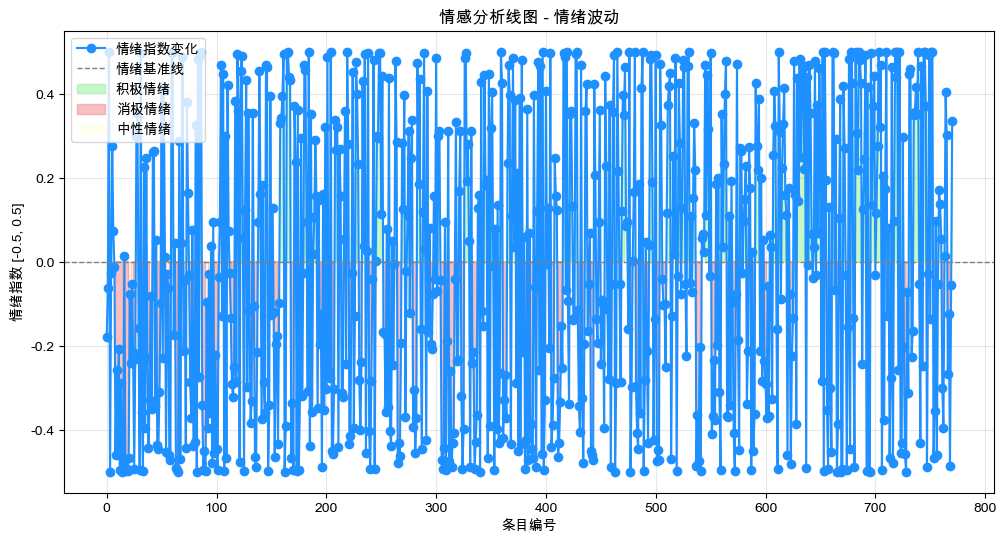

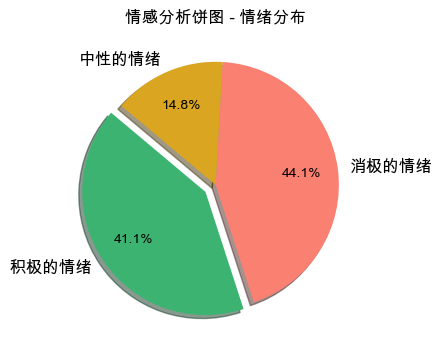

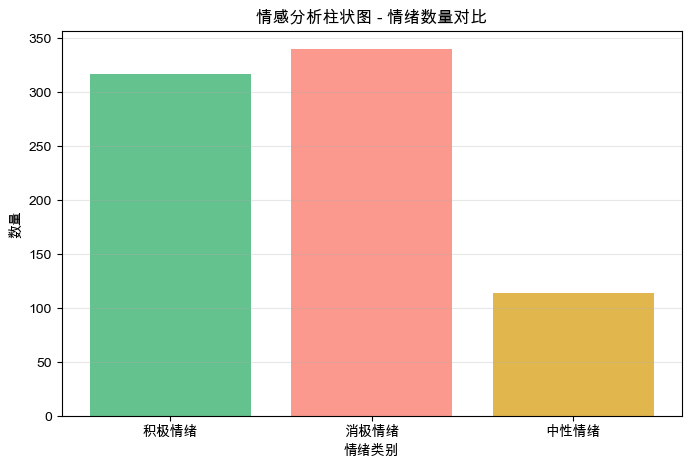

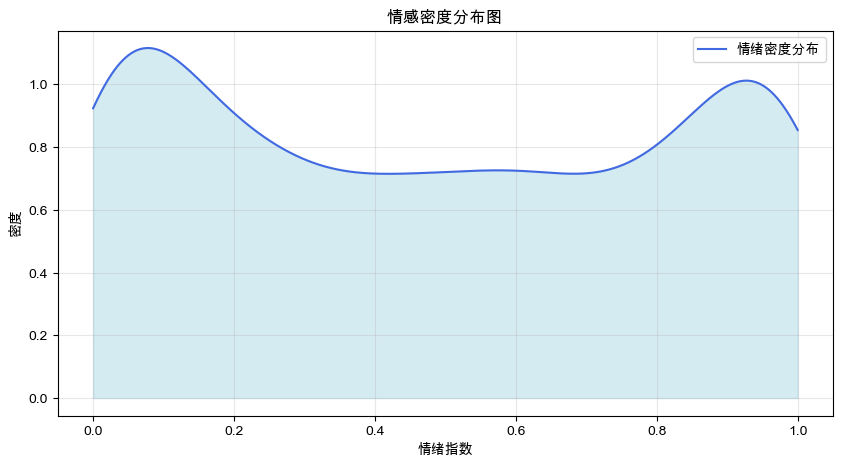

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from snownlp import SnowNLP
import random


def read_text_file(file_path):
    with open(file_path, 'r', encoding='utf-8') as file:
        lines = file.readlines()
        lines = [line.strip() for line in lines if line.strip()]  # 移除空白行
    return lines


def analyze_sentiments(source):
    sentimentslist = []
    for content in source:
        s = SnowNLP(content)
        sentimentslist.append(s.sentiments)
    return sentimentslist


def plot_sentiment_line_chart(results):
    if len(results) > 1500:
        results = random.sample(results, 800)
    plt.figure(figsize=(12, 6))
    plt.plot(np.arange(len(results)), results, marker='o', color='dodgerblue', label='情绪指数变化')
    plt.axhline(y=0, color='gray', linestyle='--', linewidth=1, label='情绪基准线')
    plt.fill_between(np.arange(len(results)), results, 0, where=(np.array(results) > 0.1), color='lightgreen',
                     alpha=0.5,
                     label='积极情绪')
    plt.fill_between(np.arange(len(results)), results, 0, where=(np.array(results) < -0.1), color='lightcoral',
                     alpha=0.5,
                     label='消极情绪')
    plt.fill_between(np.arange(len(results)), results, 0, where=(np.abs(np.array(results)) <= 0.1), color='lightyellow',
                     alpha=0.5,
                     label='中性情绪')
    plt.xlabel('条目编号')
    plt.ylabel('情绪指数 [-0.5, 0.5]')
    plt.title('情感分析线图 - 情绪波动')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.savefig('情感分析线图-丰富版.png')
    plt.show()


def plot_sentiment_pie_chart(positive_count, negative_count, neutral_count):
    labels = ['积极的情绪', '消极的情绪', '中性的情绪']
    sizes = [positive_count, negative_count, neutral_count]
    colors = ['mediumseagreen', 'salmon', 'goldenrod']
    explode = (0.1, 0, 0)  # 突出显示积极情绪部分

    plt.figure(figsize=(8, 4))
    wedges, texts, autotexts = plt.pie(
        sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%',
        shadow=True, startangle=140, textprops={'fontsize': 12}, pctdistance=0.7
    )
    plt.setp(autotexts, size=10, weight='bold', color='black')
    plt.title('情感分析饼图 - 情绪分布')
    plt.savefig('情感分析饼图-丰富版.png')
    plt.show()


def plot_bar_chart(positive_count, negative_count, neutral_count):
    categories = ['积极情绪', '消极情绪', '中性情绪']
    values = [positive_count, negative_count, neutral_count]
    colors = ['mediumseagreen', 'salmon', 'goldenrod']

    plt.figure(figsize=(8, 5))
    plt.bar(categories, values, color=colors, alpha=0.8)
    plt.xlabel('情绪类别')
    plt.ylabel('数量')
    plt.title('情感分析柱状图 - 情绪数量对比')
    plt.grid(axis='y', alpha=0.3)
    plt.savefig('情感分析柱状图.png')
    plt.show()


def plot_density_chart(sentimentslist):
    from scipy.stats import gaussian_kde

    density = gaussian_kde(sentimentslist)
    x = np.linspace(0, 1, 1000)
    y = density(x)

    plt.figure(figsize=(10, 5))
    plt.plot(x, y, color='royalblue', label='情绪密度分布')
    plt.fill_between(x, y, color='lightblue', alpha=0.5)
    plt.xlabel('情绪指数')
    plt.ylabel('密度')
    plt.title('情感密度分布图')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.savefig('情感密度分布图.png')
    plt.show()


def main(file_path):
    source = read_text_file(file_path)
    sentimentslist = analyze_sentiments(source)

    # 计算正向、反向和中性情感系数
    positive_sentiments = [x for x in sentimentslist if x > 0.6]
    negative_sentiments = [x for x in sentimentslist if x < 0.4]
    neutral_sentiments = [x for x in sentimentslist if 0.4 <= x <= 0.6]

    if positive_sentiments:
        positive_coefficient = np.mean(positive_sentiments)
    else:
        positive_coefficient = 0

    if negative_sentiments:
        negative_coefficient = np.mean(negative_sentiments)
    else:
        negative_coefficient = 0

    if neutral_sentiments:
        neutral_coefficient = np.mean(neutral_sentiments)
    else:
        neutral_coefficient = 0

    print(f"积极情感系数: {positive_coefficient}")
    print(f"消极情感系数: {negative_coefficient}")
    print(f"中性情感系数: {neutral_coefficient}")

    # 区间转换为[-0.5, 0.5]
    results = [x - 0.5 for x in sentimentslist]

    # 绘制各种图表
    plot_sentiment_line_chart(results)
    positive_count = len(positive_sentiments)
    negative_count = len(negative_sentiments)
    neutral_count = len(neutral_sentiments)
    plot_sentiment_pie_chart(positive_count, negative_count, neutral_count)
    plot_bar_chart(positive_count, negative_count, neutral_count)
    plot_density_chart(sentimentslist)


if __name__ == '__main__':
  # 设置 Matplotlib 的字体和负号显示
    plt.rcParams['font.sans-serif'] = ['Arial Unicode MS']  # macOS,用来正常显示中文标签
    plt.rcParams['axes.unicode_minus'] = False  # 用来正常显示负号
    main('data/情感分析评论数据')
